[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/10_knn_evaluation.ipynb)

# 10 · K-Nearest Neighbors & How to Evaluate a Classifier

**Part 1 — Classical supervised learning** · Notebook 10 of 27

This notebook has two halves. The first is the simplest classifier there is: **k-nearest neighbors (KNN)**. No training, no parameters, no likelihood: to classify a point, look at the $k$ closest training examples and take a vote. It's a great baseline, and it exposes two deep problems that every method faces: choosing a notion of **distance**, and the **curse of dimensionality**. The second half answers a question we've been dodging since notebook 08: **how do you tell whether a classifier is any good?** Accuracy turns out to be dangerously misleading, so we build the real toolkit: confusion matrices, precision and recall, thresholds, ROC and PR curves, calibration, and fair model comparisons.

**What you'll learn**

1. KNN from scratch, and how $k$ shapes the decision boundary
2. Choosing $k$: the bias–variance tradeoff again
3. Distance metrics, and why feature scaling is not optional
4. The **curse of dimensionality**: why "nearest" stops meaning anything
5. KNN on handwritten digits
6. Why **accuracy** lies on imbalanced data
7. The **confusion matrix**: precision, recall, F1, specificity
8. **Thresholds**: the precision–recall tradeoff
9. **ROC and PR curves**, built one threshold at a time, and what AUC really means
10. Choosing a threshold by **cost**
11. **Calibration**: reliability diagrams and the Brier score
12. Comparing classifiers fairly (ISYE 4600 HW4)

*Course map: ISYE 4600 W8 (Classification: KNN, misclassification error, confusion matrix, precision/recall/F1), W2 (distance and similarity measures), and HW4 Q1 (comparing classifiers on handwritten digits).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from sklearn.datasets import make_moons, load_digits, make_classification, load_breast_cancer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
print("Ready ✓")

CLS = [C["blue"], C["red"], C["aqua"]]
def region(ax, predict, X, y, pad=0.5, n=250, proba=False):
    x0, x1 = X[:, 0].min() - pad, X[:, 0].max() + pad; y0, y1 = X[:, 1].min() - pad, X[:, 1].max() + pad
    g1, g2 = np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))
    Z = predict(np.column_stack([g1.ravel(), g2.ravel()])).reshape(g1.shape)
    if proba:
        ax.contourf(g1, g2, Z, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.6); ax.contour(g1, g2, Z, levels=[0.5], colors=C["ink"], linewidths=1.8)
    else:
        ax.contourf(g1, g2, Z, levels=[-0.5, 0.5, 1.5], colors=[C["blue"], C["red"]], alpha=0.25); ax.contour(g1, g2, Z, levels=[0.5], colors=C["ink"], linewidths=1.5)
    ax.scatter(*X[y == 0].T, s=16, color=C["blue"], edgecolor="white", linewidth=0.5)
    ax.scatter(*X[y == 1].T, s=16, color=C["red"], edgecolor="white", linewidth=0.5)
    ax.set(xlim=(x0, x1), ylim=(y0, y1)); ax.grid(False)

Setup complete ✓


Ready ✓


---
## 1. KNN from scratch

The whole algorithm (ISYE 4600 W8: "classify a point based on the labels of its $k$ closest neighbors"):

1. **"Training":** store the training set. That's it. (KNN is a **lazy** learner: all the work happens at prediction time.)
2. **Prediction** for a new point $x$: compute its distance to every training point, find the $k$ closest, and predict the majority label among them. (For probabilities: the fraction of neighbors in each class.)

The only real code is computing all pairwise distances efficiently. Use $\|a - b\|^2 = \|a\|^2 + \|b\|^2 - 2a^\top b$ to do it as one matrix product instead of a double loop:

In [2]:
def pairwise_sq_dists(A, B):
    """Squared Euclidean distances between every row of A and every row of B, without loops."""
    return np.maximum((A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T, 0)

class KNN:
    def __init__(self, k=5): self.k = k
    def fit(self, X, y): self.X, self.y = X, y; self.classes = np.unique(y); return self     # just memorize
    def predict_proba(self, Xq):
        D = pairwise_sq_dists(Xq, self.X)
        nn = np.argpartition(D, self.k - 1, axis=1)[:, :self.k]      # indices of the k nearest (unordered)
        votes = self.y[nn]
        return np.column_stack([(votes == c).mean(1) for c in self.classes])
    def predict(self, Xq): return self.classes[self.predict_proba(Xq).argmax(1)]

Xm, ym = make_moons(300, noise=0.3, random_state=0)
ours = KNN(15).fit(Xm, ym).predict(Xm)
skl = KNeighborsClassifier(15).fit(Xm, ym).predict(Xm)
print("agreement with scikit-learn's KNN:", np.mean(ours == skl))

agreement with scikit-learn's KNN: 1.0


Here's KNN classifying one query point, step by step:

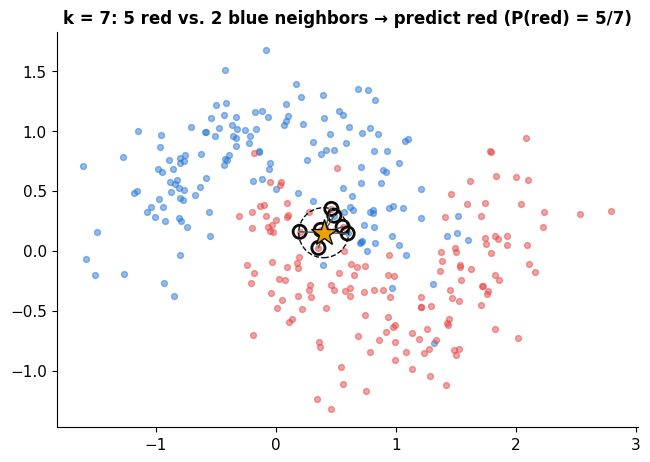

In [3]:
q = np.array([0.4, 0.15]); k_show = 7
d_q = np.sqrt(pairwise_sq_dists(q[None], Xm))[0]; nn_q = np.argsort(d_q)[:k_show]
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.scatter(*Xm[ym == 0].T, s=18, color=C["blue"], alpha=0.5); ax.scatter(*Xm[ym == 1].T, s=18, color=C["red"], alpha=0.5)
for i in nn_q:
    ax.plot([q[0], Xm[i, 0]], [q[1], Xm[i, 1]], color=C["muted"], lw=1)
ax.scatter(*Xm[nn_q].T, s=90, facecolor="none", edgecolor=C["ink"], lw=2)
ax.add_patch(plt.Circle(q, d_q[nn_q[-1]], fill=False, ls="--", color=C["ink"]))
ax.plot(*q, "*", ms=20, color=C["yellow"], markeredgecolor=C["ink"])
n_red = int(ym[nn_q].sum())
ax.set(aspect="equal", title=f"k = {k_show}: {n_red} red vs. {k_show - n_red} blue neighbors → predict {'red' if n_red > k_show/2 else 'blue'} (P(red) = {n_red}/{k_show})")
ax.grid(False); plt.show()

---
## 2. Choosing $k$: the bias–variance tradeoff again

🎚️ **Change $k$.** At $k = 1$ every training point owns its own little region (a **Voronoi** tessellation), and the boundary wraps around every noisy point. As $k$ grows, the boundary smooths out. At $k = $ the size of the training set, every query gets the same answer: the majority class.

In [4]:
def plot_knn_k(k=1):
    model = KNN(k).fit(Xm, ym)
    fig, ax = plt.subplots(figsize=(7, 5))
    region(ax, lambda P: model.predict_proba(P)[:, 1], Xm, ym, proba=True)
    ax.set(title=f"k = {k}:  training accuracy {np.mean(model.predict(Xm) == ym):.0%}")
    plt.show()

interact(plot_knn_k, k=IntSlider(value=1, min=1, max=151, step=2, description="k"));

$k = 1$ is low bias, high variance (training accuracy 100%, meaningless); large $k$ is high bias, low variance. It's the polynomial degree of notebook 06 in a different costume, and the fix is the same: **cross-validation**. Note the axis: *small* $k$ means a *more flexible* model.

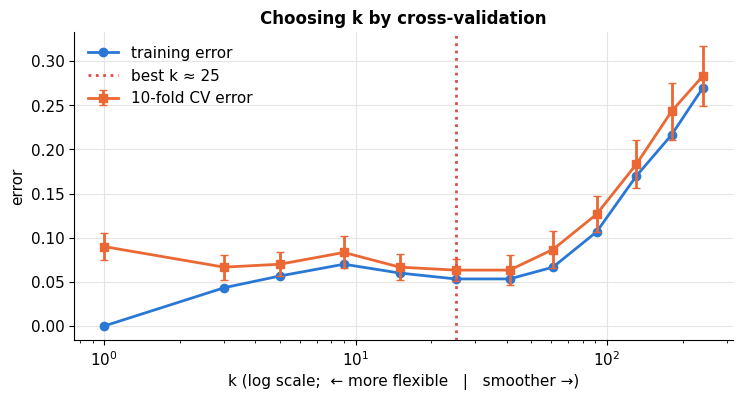

In [5]:
def cv_accuracy(model_fn, X, y, K=10, seed=0):
    folds = np.array_split(np.random.default_rng(seed).permutation(len(y)), K); accs = []
    for va in folds:
        tr = np.setdiff1d(np.arange(len(y)), va)
        accs.append(np.mean(model_fn().fit(X[tr], y[tr]).predict(X[va]) == y[va]))
    return np.mean(accs), np.std(accs, ddof=1) / np.sqrt(K)

ks = np.array([1, 3, 5, 9, 15, 25, 41, 61, 91, 131, 181, 241])
cv = np.array([cv_accuracy(lambda k=k: KNN(k), Xm, ym) for k in ks])
tr = [np.mean(KNN(k).fit(Xm, ym).predict(Xm) == ym) for k in ks]
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(ks, 1 - np.array(tr), "-o", color=C["blue"], label="training error")
ax.errorbar(ks, 1 - cv[:, 0], yerr=cv[:, 1], fmt="-s", color=C["orange"], capsize=3, label="10-fold CV error")
best_k = ks[np.argmin(1 - cv[:, 0])]
ax.axvline(best_k, color=C["red"], ls=":", label=f"best k ≈ {best_k}")
ax.set(xscale="log", xlabel="k (log scale;  ← more flexible   |   smoother →)", ylabel="error", title="Choosing k by cross-validation"); ax.legend()
plt.show()

> 🤔 **Question: Why use odd $k$?**
>
> With two classes, an odd $k$ can't produce a tie vote. With more classes ties can still happen; common tie-breakers are to shrink $k$ by one, or to weight votes by inverse distance (closer neighbors count more, scikit-learn's `weights="distance"`).

---
## 3. Distance metrics, and why feature scaling is not optional

"Nearest" depends entirely on how you measure distance. ISYE 4600 (W2, clustering) lists the common choices:

| Metric | Formula | Unit ball | Notes |
|---|---|---|---|
| Euclidean ($\ell_2$) | $\sqrt{\sum_j (a_j - b_j)^2}$ | circle | the default |
| Manhattan ($\ell_1$) | $\sum_j \lvert a_j - b_j\rvert$ | diamond | less dominated by one big difference |
| Chebyshev ($\ell_\infty$) | $\max_j \lvert a_j - b_j\rvert$ | square | worst single coordinate |
| Cosine distance | $1 - \frac{a^\top b}{\|a\|\|b\|}$ | — | ignores length; good for text and embeddings |

(Notebook 01 drew these unit balls.) The bigger practical issue is **units**. Euclidean distance adds up squared differences across features, so a feature measured in large units swamps the rest. Suppose we classify patients by age (years) and income (dollars):

KNN (k=15) on raw units (age in years, income in $): CV accuracy 55.7%
KNN (k=15) on standardized (each feature: mean 0, sd 1): CV accuracy 92.7%


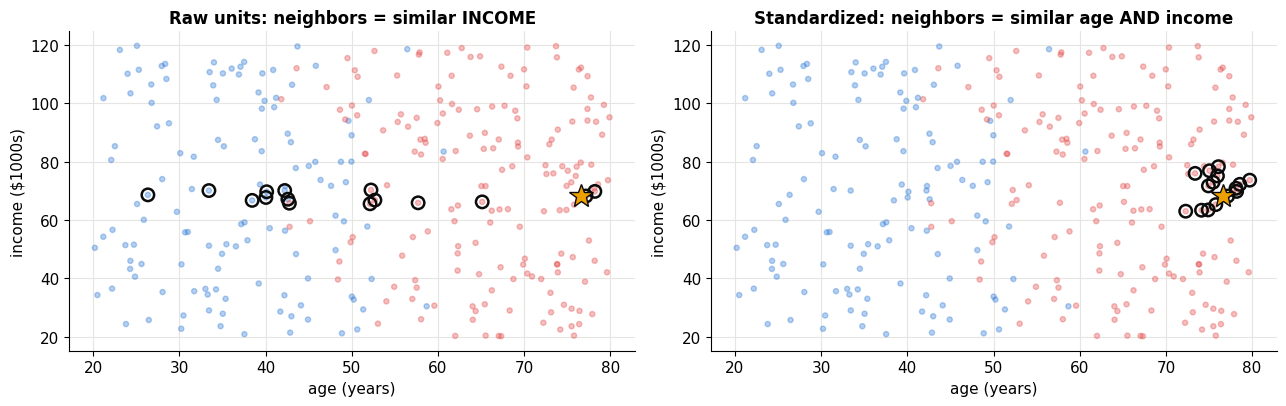

In [6]:
r_ = np.random.default_rng(4)
n_p = 300
age = r_.uniform(20, 80, n_p); income = r_.uniform(20000, 120000, n_p)
label = (age + r_.normal(0, 6, n_p) > 50).astype(int)          # the label depends ONLY on age
Xu = np.column_stack([age, income])
Zs = (Xu - Xu.mean(0)) / Xu.std(0)
for name, X_ in [("raw units (age in years, income in $)", Xu), ("standardized (each feature: mean 0, sd 1)", Zs)]:
    acc_, se_ = cv_accuracy(lambda: KNN(15), X_, label)
    print(f"KNN (k=15) on {name}: CV accuracy {acc_:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
q_i = 0
for ax, X_, title in [(axes[0], Xu, "Raw units: neighbors = similar INCOME"), (axes[1], Zs, "Standardized: neighbors = similar age AND income")]:
    d_ = np.sqrt(pairwise_sq_dists(X_[q_i:q_i + 1], X_))[0]; nn_ = np.argsort(d_)[1:16]
    ax.scatter(age, income / 1000, s=14, c=[C["red"] if l else C["blue"] for l in label], alpha=0.35)
    ax.scatter(age[nn_], income[nn_] / 1000, s=80, facecolor="none", edgecolor=C["ink"], lw=1.8)
    ax.plot(age[q_i], income[q_i] / 1000, "*", ms=18, color=C["yellow"], markeredgecolor=C["ink"])
    ax.set(xlabel="age (years)", ylabel="income ($1000s)", title=title)
fig.tight_layout(); plt.show()

With raw units, a 1-year age difference counts the same as a $1 income difference, so distances are 99.99% income. The "nearest" neighbors (circled) are people with similar incomes and **any** age, and the label depends only on age, so KNN is barely better than a coin flip. After standardizing, both features count, and accuracy jumps. **Always scale features for any distance-based method** (KNN, k-means, SVMs with RBF kernels, PCA). And just as in notebook 06: fit the scaler on the training data only.

---
## 4. The curse of dimensionality

KNN works by assuming nearby points have similar labels. In high dimensions, that assumption quietly breaks, because **everything becomes far from everything, and roughly equally far**. Three ways to see it:

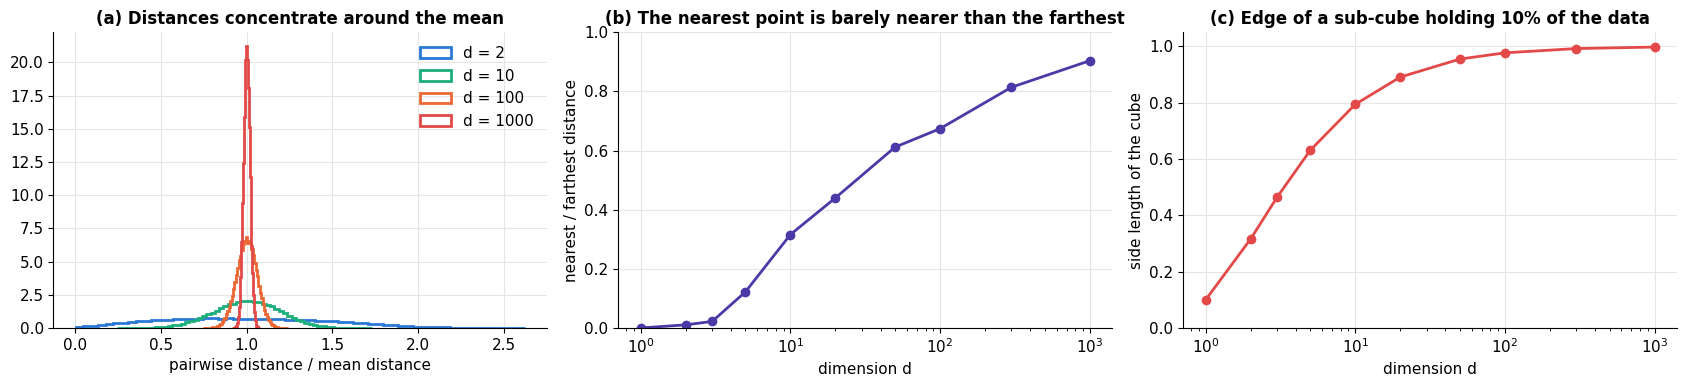

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
r_ = np.random.default_rng(0)
for d, col in zip([2, 10, 100, 1000], [C["blue"], C["aqua"], C["orange"], C["red"]]):
    P = r_.uniform(size=(400, d)); D = np.sqrt(pairwise_sq_dists(P, P))[np.triu_indices(400, 1)]
    axes[0].hist(D / D.mean(), bins=60, density=True, histtype="step", lw=2, color=col, label=f"d = {d}")
axes[0].set(xlabel="pairwise distance / mean distance", title="(a) Distances concentrate around the mean"); axes[0].legend()

dims = np.array([1, 2, 3, 5, 10, 20, 50, 100, 300, 1000])
ratio = []
for d in dims:
    P = r_.uniform(size=(1000, d)); q_ = r_.uniform(size=(1, d)); dd = np.sqrt(pairwise_sq_dists(q_, P))[0]
    ratio.append(dd.min() / dd.max())
axes[1].semilogx(dims, ratio, "-o", color=C["violet"])
axes[1].set(xlabel="dimension d", ylabel="nearest / farthest distance", ylim=(0, 1), title="(b) The nearest point is barely nearer than the farthest")

edge = np.array([[0.1 ** (1 / d) for d in dims]]).ravel()
axes[2].semilogx(dims, edge, "-o", color=C["red"])
axes[2].set(xlabel="dimension d", ylabel="side length of the cube", ylim=(0, 1.05),
            title="(c) Edge of a sub-cube holding 10% of the data")
fig.tight_layout(); plt.show()

- **(a)** In 2-D, pairwise distances range widely. In 1,000-D, almost every pair is at nearly the same distance.
- **(b)** For a random query among 1,000 points, the ratio of the nearest to the farthest distance creeps toward 1. When the nearest neighbor is only slightly closer than the farthest, "nearest" carries little information.
- **(c)** To capture the closest 10% of uniformly spread data around a point, you need a cube whose side covers 10% of the range in 1-D, 32% in 2-D, 79% in 10-D, and 99% in 100-D. A "neighborhood" that spans almost the whole range in every coordinate isn't local anymore.

What this does to KNN: add pure-noise features to the moons problem and watch accuracy decay:

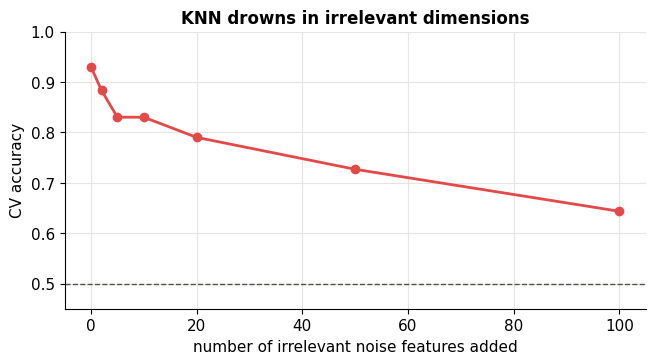

In [8]:
noise_dims = [0, 2, 5, 10, 20, 50, 100]
accs = []
for nd in noise_dims:
    Xn_ = np.hstack([(Xm - Xm.mean(0)) / Xm.std(0), np.random.default_rng(1).normal(size=(len(Xm), nd))])
    accs.append(cv_accuracy(lambda: KNN(15), Xn_, ym)[0])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(noise_dims, accs, "-o", color=C["red"]); ax.axhline(0.5, color=C["muted"], ls="--", lw=1)
ax.set(xlabel="number of irrelevant noise features added", ylabel="CV accuracy", ylim=(0.45, 1), title="KNN drowns in irrelevant dimensions")
plt.show()

Two real features carry all the signal, but each noise feature adds random distance, and by 100 noise features the neighbors are essentially random. Methods that **learn** which features matter (logistic regression's weights, trees' splits, the Lasso) cope far better. For KNN, the remedies are feature selection (notebook 07), dimensionality reduction (notebook 16), or learned embeddings, where a neural network maps data into a space in which distance *is* meaningful. (That last one is how modern image search and retrieval-augmented LLMs work: KNN in a learned embedding space.)

> 🤔 **Question: Then why does KNN work at all on images, which have thousands of pixels?**
>
> Because real data isn't spread uniformly through its space. Images of digits occupy a thin, low-dimensional region (a "manifold") inside the 64- or 784-dimensional pixel space: most random pixel arrays look like static, not digits. Distances *along* that region can still be meaningful. The curse bites hardest when data really fills many dimensions, or when many features are noise.

---
## 5. KNN on handwritten digits

KNN (k=3) test accuracy on 8×8 digits: 98.8%   (no training at all!)


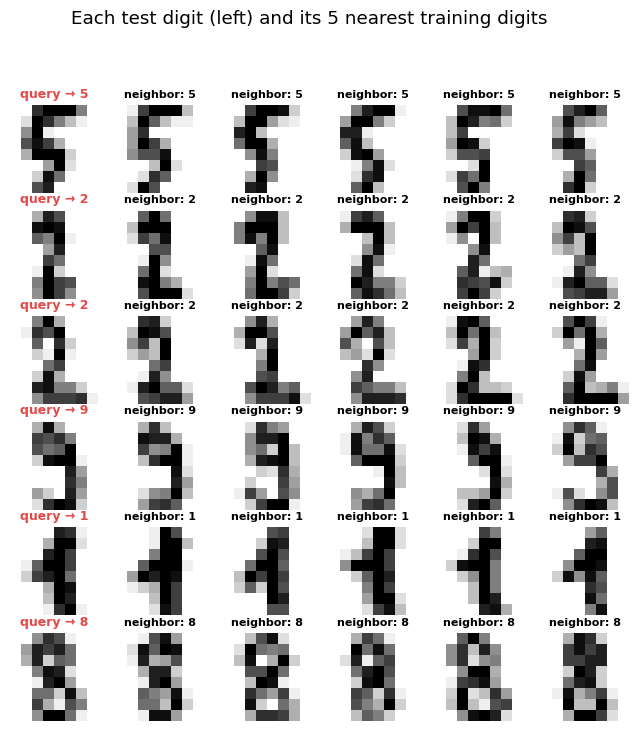

In [9]:
dg = load_digits(); Xd, yd = dg.data, dg.target
perm = np.random.default_rng(0).permutation(len(yd)); trd, ted = perm[:1300], perm[1300:]
knn_d = KNN(3).fit(Xd[trd], yd[trd])
pred_d = knn_d.predict(Xd[ted])
print(f"KNN (k=3) test accuracy on 8×8 digits: {np.mean(pred_d == yd[ted]):.1%}   (no training at all!)")

Dq = pairwise_sq_dists(Xd[ted[:6]], Xd[trd])
fig, axes = plt.subplots(6, 6, figsize=(8, 8))
for r in range(6):
    axes[r, 0].imshow(Xd[ted[r]].reshape(8, 8), cmap="gray_r"); axes[r, 0].set_title(f"query → {pred_d[r]}", fontsize=9, color=C["red"])
    for c, j in enumerate(np.argsort(Dq[r])[:5], start=1):
        axes[r, c].imshow(Xd[trd][j].reshape(8, 8), cmap="gray_r"); axes[r, c].set_title(f"neighbor: {yd[trd][j]}", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
fig.suptitle("Each test digit (left) and its 5 nearest training digits", y=1.0); plt.show()

98–99% accuracy with zero training, beating the softmax regression from notebook 08. The pixel-space neighbors really are the same digit drawn similarly. The costs: prediction must compare against **every** training example ($O(md)$ per query, which is why large-scale systems use approximate nearest-neighbor indexes like FAISS), and the whole training set must be kept in memory.

---
## 6. Why accuracy lies

Now the second half: evaluation. ISYE 4600 (W8) starts with the **misclassification error** (or its complement, accuracy): the fraction of predictions that are wrong. It treats every mistake the same and, as ISYE puts it, "can be misleading for imbalanced datasets." Here's how misleading. A fraud-detection problem where 1% of transactions are fraud:

In [10]:
Xf, yf = make_classification(n_samples=20000, n_features=12, n_informative=6, weights=[0.99, 0.01], class_sep=1.0, flip_y=0.002, random_state=3)
perm = np.random.default_rng(0).permutation(len(yf)); trf, tef = perm[:12000], perm[12000:]
print(f"fraud rate: {yf.mean():.2%}")
always_legit = np.zeros(len(tef), int)
lr_f = LogisticRegression(max_iter=3000).fit(Xf[trf], yf[trf])
p_f = lr_f.predict_proba(Xf[tef])[:, 1]
for name, pred in [("'always predict legit' (does nothing)", always_legit), ("logistic regression (threshold 0.5)", (p_f > 0.5).astype(int))]:
    caught = pred[yf[tef] == 1].mean()
    print(f"{name:42s} accuracy {np.mean(pred == yf[tef]):.2%}   fraud caught: {caught:.0%}")

fraud rate: 1.11%
'always predict legit' (does nothing)      accuracy 98.89%   fraud caught: 0%
logistic regression (threshold 0.5)        accuracy 99.10%   fraud caught: 24%


A model that does **nothing** scores 99% accuracy and catches zero fraud. The real model's accuracy is only a fraction of a percent higher, which completely hides the fact that it catches about a quarter of the fraud (and, as section 8 will show, could catch far more with a different threshold). Accuracy is dominated by the majority class. We need metrics that look at each kind of mistake separately.

---
## 7. The confusion matrix: precision, recall, F1

For two classes ("positive" = the class we're hunting for: fraud, disease, spam), every prediction falls into one of four cells:

| | **predicted positive** | **predicted negative** |
|---|---|---|
| **actually positive** | **TP** (true positive): caught it | **FN** (false negative): missed it |
| **actually negative** | **FP** (false positive): false alarm | **TN** (true negative): correctly ignored |

From these come the metrics (ISYE 4600 W8):

- **Precision** $= \dfrac{TP}{TP + FP}$: of everything flagged, how much was real? ("How many selected items are relevant?")
- **Recall** (sensitivity, true positive rate) $= \dfrac{TP}{TP + FN}$: of everything real, how much did we catch? ("How many relevant items are selected?")
- **Specificity** (true negative rate) $= \dfrac{TN}{TN + FP}$; and the **false positive rate** $= 1 -$ specificity.
- **F1 score** $= \dfrac{2}{1/\text{precision} + 1/\text{recall}}$: the **harmonic** mean, which is high only if *both* are high (the harmonic mean is dragged down by the smaller of the two).

Which matters more depends on the cost of each mistake. A cancer screen wants high **recall** (missing a cancer is terrible; a false alarm means a follow-up test). A spam filter wants high **precision** (sending a real email to spam is worse than letting some spam through).

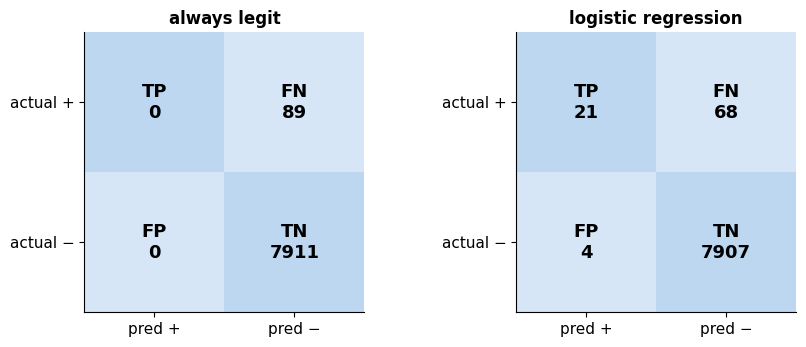

,always legit,logistic regression
accuracy,0.989,0.991
precision,0.000,0.840
recall,0.000,0.236
specificity,1.000,0.999
F1,0.000,0.368


In [11]:
def confusion(y_true, y_pred):
    tp = int(np.sum((y_pred == 1) & (y_true == 1))); fn = int(np.sum((y_pred == 0) & (y_true == 1)))
    fp = int(np.sum((y_pred == 1) & (y_true == 0))); tn = int(np.sum((y_pred == 0) & (y_true == 0)))
    return tp, fn, fp, tn

def metrics(y_true, y_pred):
    tp, fn, fp, tn = confusion(y_true, y_pred)
    prec = tp / (tp + fp) if tp + fp else 0.0; rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(accuracy=(tp + tn) / len(y_true), precision=prec, recall=rec, specificity=tn / (tn + fp), F1=f1)

def draw_confusion(ax, y_true, y_pred, title=""):
    tp, fn, fp, tn = confusion(y_true, y_pred)
    M = np.array([[tp, fn], [fp, tn]])
    ax.imshow([[1, 0], [0, 1]], cmap=matplotlib_cmap, vmin=-1, vmax=2)
    for (i, j), v, lab in zip([(0, 0), (0, 1), (1, 0), (1, 1)], M.ravel(), ["TP", "FN", "FP", "TN"]):
        ax.text(j, i, f"{lab}\n{v}", ha="center", va="center", fontsize=13, fontweight="bold")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["pred +", "pred −"], yticklabels=["actual +", "actual −"], title=title); ax.grid(False)

from matplotlib.colors import ListedColormap
matplotlib_cmap = ListedColormap(["#f6d3d3", "#d6e6f6", "#bcd7ef", "#bcd7ef"])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (name, pred) in zip(axes, [("always legit", always_legit), ("logistic regression", (p_f > 0.5).astype(int))]):
    draw_confusion(ax, yf[tef], pred, name)
fig.tight_layout(); plt.show()
pd.DataFrame({name: metrics(yf[tef], pred) for name, pred in [("always legit", always_legit), ("logistic regression", (p_f > 0.5).astype(int))]}).round(3)

Now the difference is obvious: the do-nothing model has recall 0, and precision and F1 are undefined/zero. Accuracy hid all of that.

### Multi-class

With $K$ classes the confusion matrix is $K\times K$ (rows = true class, columns = predicted, as in notebook 08's digits). Precision and recall are computed **per class** (one class vs. the rest), then averaged: **macro** averaging gives every class equal weight (good when rare classes matter), **micro** averaging pools all the counts (dominated by common classes; for single-label problems it equals accuracy).

---
## 8. Thresholds: the precision–recall tradeoff

A probabilistic classifier doesn't output a decision, it outputs a **score**. The decision comes from comparing it with a **threshold** $t$, and nothing says $t$ must be 0.5. Lower the threshold and you flag more cases: recall goes up, precision usually goes down. Raise it and the reverse happens.

🎚️ **Slide the threshold.** The histograms show the model's scores for real fraud (red) and legitimate transactions (blue). Everything right of the line gets flagged.

In [12]:
def plot_threshold(t=0.5):
    yt_ = yf[tef]; pred = (p_f >= t).astype(int); m_ = metrics(yt_, pred)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3.9), gridspec_kw=dict(width_ratios=[2.2, 1]))
    bins = np.linspace(0, 1, 51)
    ax1.hist(p_f[yt_ == 0], bins=bins, color=C["blue"], alpha=0.6, label="legit (negative)", log=True)
    ax1.hist(p_f[yt_ == 1], bins=bins, color=C["red"], alpha=0.7, label="fraud (positive)", log=True)
    ax1.axvline(t, color=C["ink"], lw=2.5)
    ax1.set(xlabel="predicted P(fraud)", ylabel="count (log)", title=f"threshold {t:.2f}:  precision {m_['precision']:.2f},  recall {m_['recall']:.2f},  F1 {m_['F1']:.2f}")
    ax1.legend(loc="upper center")
    draw_confusion(ax2, yt_, pred, f"accuracy {m_['accuracy']:.3f}")
    fig.tight_layout(); plt.show()

interact(plot_threshold, t=FloatSlider(value=0.5, min=0.0, max=1.0, step=0.01, description="threshold"));

At $t = 0.5$ the model misses a big chunk of fraud. Lower it to ~0.1 and recall jumps while precision drops: more alarms, more of them false. There's no free lunch; the threshold is a **business decision**, not a modeling one (section 10 makes it precise).

---
## 9. ROC and PR curves

Instead of picking one threshold, summarize the classifier across **all** thresholds:

- **ROC curve:** true positive rate (recall) vs. false positive rate, as the threshold sweeps from 1 down to 0. It starts at (0, 0) (flag nothing) and ends at (1, 1) (flag everything). A random classifier follows the diagonal; a perfect one hugs the top-left corner.
- **Precision–recall (PR) curve:** precision vs. recall over the same sweep.

Building the ROC curve takes one sort: order the examples by score, then walk down the list. Each positive moves the curve up by $1/P$; each negative moves it right by $1/N$.

In [13]:
def roc_curve_ours(y, s):
    order = np.argsort(-s); y_sorted = y[order]
    tps = np.r_[0, np.cumsum(y_sorted)]; fps = np.r_[0, np.cumsum(1 - y_sorted)]
    return fps / fps[-1], tps / tps[-1], np.r_[np.inf, s[order]]

def pr_curve_ours(y, s):
    order = np.argsort(-s); y_sorted = y[order]
    tps = np.cumsum(y_sorted); k = np.arange(1, len(y) + 1)
    return tps / tps[-1], tps / k                      # recall, precision at each cutoff

def auc_trapezoid(x, y_):
    return np.sum(np.diff(x) * (y_[1:] + y_[:-1]) / 2)

# Animate the ROC walk on a small sample so individual steps are visible
r_ = np.random.default_rng(2)
small = np.r_[r_.choice(np.where(yf[tef] == 1)[0], 25, replace=False), r_.choice(np.where(yf[tef] == 0)[0], 60, replace=False)]
ys_, ss_ = yf[tef][small], p_f[small]
fpr_s, tpr_s, thr_s = roc_curve_ours(ys_, ss_)
order_s = np.argsort(-ss_)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), dpi=72, gridspec_kw=dict(width_ratios=[1.3, 1]))
ax1.scatter(np.arange(len(ys_)), ss_[order_s], c=[C["red"] if v else C["blue"] for v in ys_[order_s]], s=22)
cut = ax1.axvline(-0.5, color=C["ink"], lw=2)
ax1.set(xlabel="examples sorted by score (highest first)", ylabel="score", title="Lower the threshold one example at a time")
ax2.plot([0, 1], [0, 1], color=C["muted"], ls="--", lw=1)
roc_line, = ax2.plot([], [], color=C["violet"], lw=2.5); dot, = ax2.plot([], [], "o", color=C["violet"], ms=8)
ax2.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), xlabel="false positive rate", ylabel="true positive rate (recall)", aspect="equal")
ttl = ax2.set_title("")
def frame(i):
    cut.set_xdata([i - 0.5, i - 0.5]); roc_line.set_data(fpr_s[:i + 1], tpr_s[:i + 1]); dot.set_data([fpr_s[i]], [tpr_s[i]])
    ttl.set_text(f"flagged {i}:  TPR {tpr_s[i]:.2f},  FPR {fpr_s[i]:.2f}")
    return cut, roc_line, dot
fig.tight_layout()
show_anim(animation.FuncAnimation(fig, frame, frames=list(range(0, len(ys_) + 1, 2)) + [len(ys_)], interval=140))

Every red point (a positive) is a step **up**, every blue point (a negative) a step **right**. A good classifier ranks most positives above most negatives, so the walk goes up first and right later, bowing toward the top-left.

**AUC** (area under the ROC curve) summarizes it in one number with a lovely interpretation: **AUC = the probability that a randomly chosen positive gets a higher score than a randomly chosen negative.** 0.5 is random ranking, 1.0 is perfect. Check it on the full test set:

AUC by area under the curve:            0.8572
P(score of random positive > negative): 0.8572   ← the same number


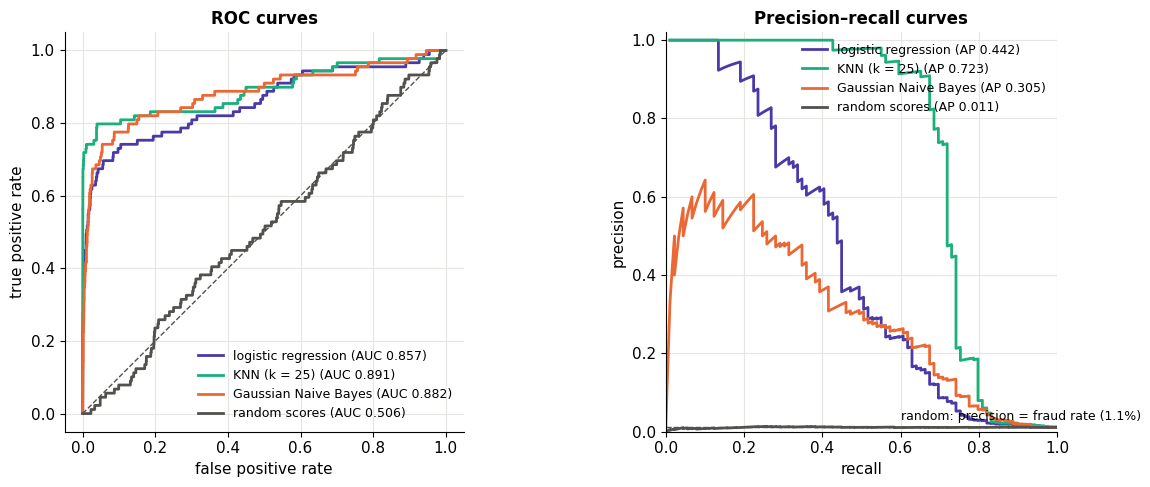

In [14]:
yt_ = yf[tef]
fpr, tpr, _ = roc_curve_ours(yt_, p_f)
auc = auc_trapezoid(fpr, tpr)
pos, neg = p_f[yt_ == 1], p_f[yt_ == 0]
pairwise = np.mean(pos[:, None] > neg[None, :]) + 0.5 * np.mean(pos[:, None] == neg[None, :])
print(f"AUC by area under the curve:            {auc:.4f}")
print(f"P(score of random positive > negative): {pairwise:.4f}   ← the same number")

models_f = {"logistic regression": p_f,
            "KNN (k = 25)": KNeighborsClassifier(25).fit(Xf[trf], yf[trf]).predict_proba(Xf[tef])[:, 1],
            "Gaussian Naive Bayes": GaussianNB().fit(Xf[trf], yf[trf]).predict_proba(Xf[tef])[:, 1],
            "random scores": np.random.default_rng(0).random(len(tef))}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for (name, s_), col in zip(models_f.items(), [C["violet"], C["aqua"], C["orange"], C["muted"]]):
    fpr_, tpr_, _ = roc_curve_ours(yt_, s_); rec_, prec_ = pr_curve_ours(yt_, s_)
    ap = np.sum(np.diff(np.r_[0, rec_]) * prec_)                     # average precision
    ax1.plot(fpr_, tpr_, color=col, lw=2, label=f"{name} (AUC {auc_trapezoid(fpr_, tpr_):.3f})")
    ax2.plot(rec_, prec_, color=col, lw=2, label=f"{name} (AP {ap:.3f})")
ax1.plot([0, 1], [0, 1], color=C["muted"], ls="--", lw=1)
ax1.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curves", aspect="equal"); ax1.legend(fontsize=9, loc="lower right")
ax2.axhline(yt_.mean(), color=C["muted"], ls="--", lw=1); ax2.text(0.6, yt_.mean() + 0.02, f"random: precision = fraud rate ({yt_.mean():.1%})", fontsize=9)
ax2.set(xlabel="recall", ylabel="precision", title="Precision–recall curves", xlim=(0, 1), ylim=(0, 1.02), aspect="equal"); ax2.legend(fontsize=9, loc="upper right")
fig.tight_layout(); plt.show()

**ROC or PR?** On heavily imbalanced data, the ROC curve can look rosy, because the false positive rate divides by the huge number of negatives: even thousands of false alarms barely move it. The PR curve uses precision instead, which is exactly what suffers when false alarms swamp the few real positives. Notice how much more the models differ on the right: KNN is clearly best at finding the rare fraud cases, which the near-identical ROC curves barely hint at. Rule of thumb: **use PR curves (and average precision) when positives are rare and you care about them**; ROC/AUC is fine for balanced problems and for comparing rankings.

---
## 10. Choosing a threshold by cost

Suppose a missed fraud (FN) costs \$500 and a false alarm (FP) costs \$10 of an analyst's time. Then the right threshold minimizes the **expected cost**, not the error rate:

$$\text{cost}(t) = 500\cdot FN(t) + 10\cdot FP(t)$$

There's even a closed-form answer if the probabilities are calibrated: flag a case when the expected cost of ignoring it exceeds the expected cost of flagging it, $p\cdot 500 > (1 - p)\cdot 10$, i.e. when $p > \frac{10}{510} \approx 0.02$. That's the threshold implied by **decision theory**, and it's nowhere near 0.5.

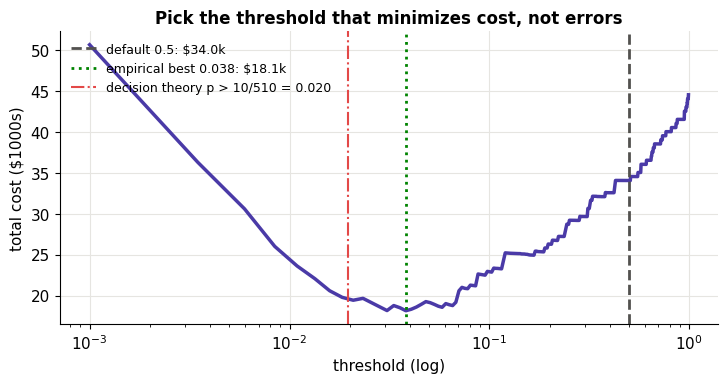

In [15]:
c_fn, c_fp = 500, 10
ts = np.linspace(0.001, 0.99, 400)
costs = np.array([c_fn * confusion(yt_, (p_f >= t).astype(int))[1] + c_fp * confusion(yt_, (p_f >= t).astype(int))[2] for t in ts])
t_best = ts[np.argmin(costs)]; t_theory = c_fp / (c_fp + c_fn)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(ts, costs / 1000, color=C["violet"], lw=2.5)
ax.axvline(0.5, color=C["muted"], ls="--", label=f"default 0.5: ${costs[np.argmin(np.abs(ts - 0.5))]/1000:.1f}k")
ax.axvline(t_best, color=C["green"], ls=":", lw=2, label=f"empirical best {t_best:.3f}: ${costs.min()/1000:.1f}k")
ax.axvline(t_theory, color=C["red"], ls="-.", lw=1.5, label=f"decision theory p > 10/510 = {t_theory:.3f}")
ax.set(xscale="log", xlabel="threshold (log)", ylabel="total cost ($1000s)", title="Pick the threshold that minimizes cost, not errors"); ax.legend(fontsize=9)
plt.show()

The cost-optimal threshold sits close to the decision-theory value and saves a large fraction of the cost of the default 0.5. (One caveat: the theory assumes the probabilities are **calibrated**, which is the next topic.)

> 🤔 **Question: Shouldn't I just rebalance the training data (oversample fraud) instead?**
>
> Resampling or class weights (`class_weight="balanced"`) shift the model's probabilities, which is roughly equivalent to moving the threshold. Moving the threshold on a well-calibrated model is usually cleaner: you keep honest probabilities and make the cost tradeoff explicit. Resampling can help some models train (very rare classes can get too little gradient signal), but it isn't a substitute for choosing the threshold deliberately.

---
## 11. Calibration: reliability diagrams and the Brier score

A model is **calibrated** if its probabilities mean what they say: among cases scored 0.3, about 30% are positive. Rankings (AUC) don't care about calibration, but **decisions** do (section 10's formula assumed it). The **reliability diagram** bins predictions and plots predicted vs. observed frequency; the **Brier score** $\frac1m\sum_i (p^i - y^i)^2$ is the mean squared error of the probabilities (lower is better, and it rewards both calibration and sharpness).

A balanced dataset with plenty of test points keeps the bins meaningful:

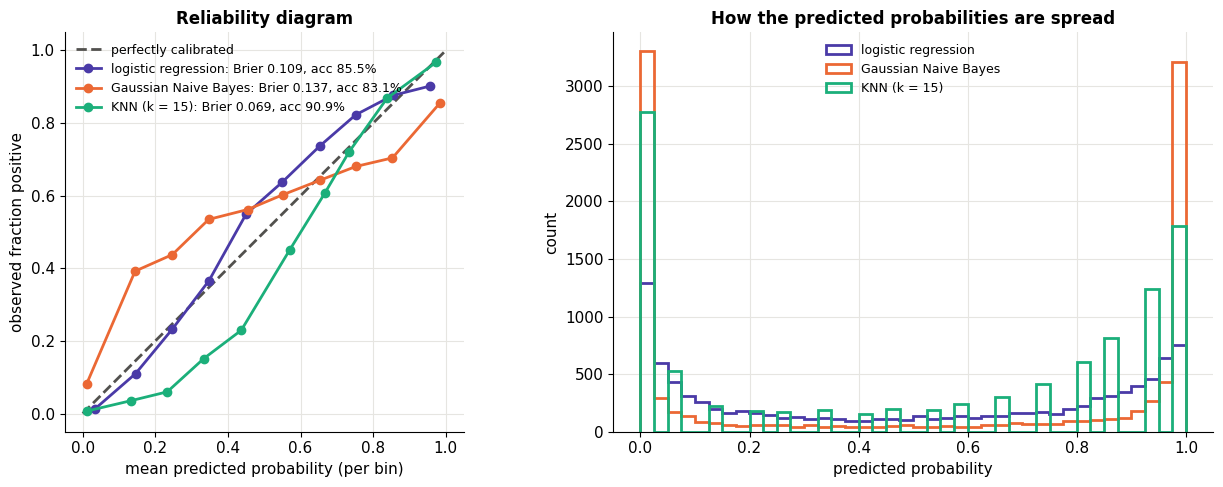

In [16]:
Xc, yc = make_classification(n_samples=20000, n_features=20, n_informative=6, n_redundant=6, class_sep=0.8, random_state=0)
trc, tec = np.arange(10000), np.arange(10000, 20000)
probs = {"logistic regression": LogisticRegression(max_iter=3000).fit(Xc[trc], yc[trc]).predict_proba(Xc[tec])[:, 1],
         "Gaussian Naive Bayes": GaussianNB().fit(Xc[trc], yc[trc]).predict_proba(Xc[tec])[:, 1],
         "KNN (k = 15)": KNeighborsClassifier(15).fit(Xc[trc], yc[trc]).predict_proba(Xc[tec])[:, 1]}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.plot([0, 1], [0, 1], color=C["muted"], ls="--", label="perfectly calibrated")
bins = np.linspace(0, 1, 11)
for (name, pr), col in zip(probs.items(), [C["violet"], C["orange"], C["aqua"]]):
    idx = np.clip(np.digitize(pr, bins) - 1, 0, 9)
    xs_, ys_ = zip(*[(pr[idx == b].mean(), yc[tec][idx == b].mean()) for b in range(10) if np.sum(idx == b) > 20])
    brier = np.mean((pr - yc[tec]) ** 2); acc_ = np.mean((pr > 0.5) == yc[tec])
    ax1.plot(xs_, ys_, "-o", color=col, lw=2, label=f"{name}: Brier {brier:.3f}, acc {acc_:.1%}")
    ax2.hist(pr, bins=40, histtype="step", lw=2, color=col, label=name)
ax1.set(xlabel="mean predicted probability (per bin)", ylabel="observed fraction positive", title="Reliability diagram", aspect="equal"); ax1.legend(fontsize=9, loc="upper left")
ax2.set(xlabel="predicted probability", ylabel="count", title="How the predicted probabilities are spread"); ax2.legend(fontsize=9)
fig.tight_layout(); plt.show()

- **Logistic regression** sits close to the diagonal: maximum likelihood rewards honest probabilities.
- **Naive Bayes** forms an S-shape away from the diagonal: its probabilities are too extreme (piled up near 0 and 1, right panel), the double-counting of correlated evidence from notebook 09. It can still rank reasonably well.
- **KNN** produces coarse probabilities (multiples of $1/k$).

A miscalibrated model can be fixed after the fact by fitting a small 1-D model from its scores to the observed outcomes on held-out data: **Platt scaling** (a logistic regression on the score) or **isotonic regression** (scikit-learn's `CalibratedClassifierCV`).

---
## 12. Comparing classifiers fairly (ISYE 4600 HW4)

ISYE 4600's HW4 compares classifiers on handwritten digits. Doing that honestly needs three things from notebook 06 and this one: the **same** folds for every model, a **spread** (not just one number), and the **right metric**. Here are five classifiers on the digits under 10-fold CV:

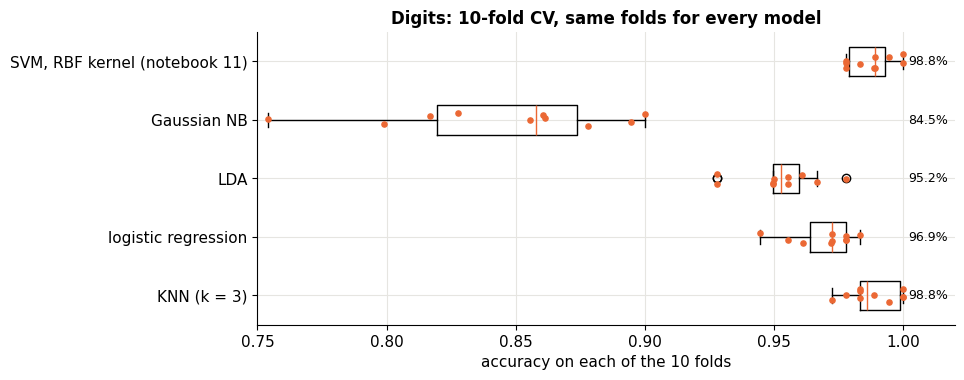

SVM − KNN, per fold: [ 0.017 -0.011  0.006  0.     0.006  0.    -0.006 -0.022  0.     0.006]
mean difference -0.056%, SVM better on 4 of 10 folds, tied on 3


In [17]:
from sklearn.svm import SVC
Xs_d = Xd / 16.0
contenders = {"KNN (k = 3)": lambda: KNeighborsClassifier(3), "logistic regression": lambda: LogisticRegression(max_iter=5000),
              "LDA": lambda: LinearDiscriminantAnalysis(), "Gaussian NB": lambda: GaussianNB(), "SVM, RBF kernel (notebook 11)": lambda: SVC()}
folds = np.array_split(np.random.default_rng(0).permutation(len(yd)), 10)
scores = {}
for name, mk in contenders.items():
    accs = []
    for va in folds:
        tr_ = np.setdiff1d(np.arange(len(yd)), va)
        accs.append(mk().fit(Xs_d[tr_], yd[tr_]).score(Xs_d[va], yd[va]))
    scores[name] = np.array(accs)

fig, ax = plt.subplots(figsize=(9, 3.8))
names = list(scores); data = [scores[n_] for n_ in names]
ax.boxplot(data, vert=False, tick_labels=names, widths=0.5)
for i, d_ in enumerate(data, 1):
    ax.scatter(d_, np.full(len(d_), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(d_)), s=14, color=C["orange"], zorder=3)
    ax.text(1.002, i, f"{d_.mean():.1%}", va="center", fontsize=9)
ax.set(xlabel="accuracy on each of the 10 folds", xlim=(0.75, 1.02), title="Digits: 10-fold CV, same folds for every model")
plt.show()

diff = scores["SVM, RBF kernel (notebook 11)"] - scores["KNN (k = 3)"]
print(f"SVM − KNN, per fold: {np.round(diff, 3)}")
print(f"mean difference {diff.mean():+.3%}, SVM better on {np.sum(diff > 0)} of 10 folds, tied on {np.sum(diff == 0)}")

Because every model saw the same folds, we can compare them **fold by fold** (a paired comparison), which is much more sensitive than comparing two averages with overlapping error bars. Gaussian Naive Bayes trails badly (its independence assumption is terrible for neighboring pixels, notebook 09); KNN and the SVM are close at the top.

> 🤔 **Question: Is a 0.5% accuracy difference "real"?**
>
> Check whether it's consistent across folds (as above), or use a paired test such as McNemar's test on a single held-out set. Even then, ask whether it matters: a model that's 0.5% more accurate but 100× slower at prediction time (like KNN on a huge dataset) may be the worse choice. Accuracy is one column in the decision, next to speed, memory, interpretability and calibration.

---
## 13. Summary

**KNN:** store the data; predict by majority vote of the $k$ nearest points. Small $k$ = flexible (high variance), large $k$ = smooth (high bias); choose by CV. Scale your features. Beware high dimensions: distances concentrate and neighborhoods stop being local.

**Evaluation:**

| Tool | Answers | Use when |
|---|---|---|
| Accuracy | what fraction is right? | balanced classes, equal costs |
| Confusion matrix | which mistakes? | always look at it |
| Precision / recall / F1 | how pure are the flags / how many did we catch? | one class matters more |
| Threshold sweep | what tradeoffs are available? | turning scores into decisions |
| ROC / AUC | how well does it **rank**? | balanced-ish problems, comparing rankers |
| PR curve / AP | ranking quality on the rare class | rare positives |
| Cost curve | which threshold is best for *my* costs? | you know (roughly) what mistakes cost |
| Reliability diagram / Brier | are the probabilities honest? | decisions depend on probabilities |
| Paired CV comparison | is model A really better than B? | choosing between models |

### ✏️ Exercises

1. Implement **distance-weighted** KNN (each neighbor votes with weight $1/d$) and compare its CV accuracy curve over $k$ with plain KNN on the moons.
2. Implement **KNN regression** (average the neighbors' $y$) on notebook 05's sine data. How does the fitted curve change with $k$?
3. Prove that AUC equals the probability that a random positive outranks a random negative. *(Hint: each step up in the ROC walk adds a column of height $1/P$ for every negative already passed.)*
4. On the fraud data, compute macro- and micro-averaged F1 for the "always legit" model. Why are they so different?
5. Calibrate the Naive Bayes model from section 11 with Platt scaling (fit a logistic regression from its log-odds to the labels on a held-out split) and redraw its reliability curve.
6. Add 20 noise features to the digits data and rerun the comparison in section 12. Which models suffer most, and why?

### References

- ISYE 4600 W8 (Classification: KNN, misclassification error, confusion matrix, precision/recall/F1) and W2 (distance metrics); HW4 Q1 (comparing classifiers on handwritten digits).
- T. Cover & P. Hart, *Nearest Neighbor Pattern Classification*, IEEE Trans. Information Theory (1967).
- K. Beyer et al., *When Is "Nearest Neighbor" Meaningful?*, ICDT (1999).
- T. Fawcett, *An Introduction to ROC Analysis*, Pattern Recognition Letters (2006).
- T. Saito & M. Rehmsmeier, *The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets*, PLOS ONE (2015).
- A. Niculescu-Mizil & R. Caruana, *Predicting Good Probabilities with Supervised Learning*, ICML (2005).

**Next → [11 · Support Vector Machines](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/11_svm.ipynb)**